In [1]:
from pathlib import Path
import sys

# El kernel puede arrancar en notebooks/ o en la raíz del repo.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

if not (raiz / "src" / "pronostico_geomagnetico").is_dir():
    raise FileNotFoundError(f"No encuentro el código del proyecto en: {raiz}")

sys.path.insert(0, str(raiz))

In [2]:
from pathlib import Path

from src.pronostico_geomagnetico.loader import load_omni
from src.pronostico_geomagnetico.validator import validate_omni
from src.pronostico_geomagnetico.preprocessor import preprocess_omni

ruta = raiz / "data" / "raw" / "omni2_2000.dat"

df = load_omni(ruta)
validate_omni(df)
df_clean = preprocess_omni(df)

print(df_clean.shape)
df_clean[["year", "day_of_year", "hour", "kp_x10"]].head(6)

(8784, 55)


,year,day_of_year,hour,kp_x10
0,2000,1,0,53
1,2000,1,1,53
2,2000,1,2,53
3,2000,1,3,47
4,2000,1,4,47
5,2000,1,5,47


In [3]:
import pandas as pd

df_temporal = df_clean.copy()

inicio_anio = pd.to_datetime(df_temporal["year"].astype(str), format="%Y", utc=True)
df_temporal["timestamp"] = (
    inicio_anio
    + pd.to_timedelta(df_temporal["day_of_year"] - 1, unit="D")
    + pd.to_timedelta(df_temporal["hour"], unit="h")
)

df_temporal[["timestamp", "kp_x10"]].head(6)

,timestamp,kp_x10
0,2000-01-01 00:00:00+00:00,53
1,2000-01-01 01:00:00+00:00,53
2,2000-01-01 02:00:00+00:00,53
3,2000-01-01 03:00:00+00:00,47
4,2000-01-01 04:00:00+00:00,47
5,2000-01-01 05:00:00+00:00,47


In [4]:
# 00:00, 01:00 y 02:00 pertenecen al bloque que empieza a las 00:00.
df_temporal["bloque_kp"] = df_temporal["timestamp"].dt.floor("3h")

bloques = df_temporal.groupby("bloque_kp").agg(
    horas=("kp_x10", "size"),
    kp_presentes=("kp_x10", "count"),
    kp_distintos=("kp_x10", "nunique"),
    kp_x10=("kp_x10", "first"),
)

bloques.head(8)

,horas,kp_presentes,kp_distintos,kp_x10
bloque_kp,,,,
2000-01-01 00:00:00+00:00,3,3,1,53
2000-01-01 03:00:00+00:00,3,3,1,47
2000-01-01 06:00:00+00:00,3,3,1,40
2000-01-01 09:00:00+00:00,3,3,1,33
2000-01-01 12:00:00+00:00,3,3,1,43
2000-01-01 15:00:00+00:00,3,3,1,30
2000-01-01 18:00:00+00:00,3,3,1,43
2000-01-01 21:00:00+00:00,3,3,1,37


In [5]:
bloque_valido = (
    (bloques["horas"] == 3)
    & (bloques["kp_presentes"] == 3)
    & (bloques["kp_distintos"] == 1)
)

print("Bloques totales:", len(bloques))
print("Bloques no válidos:", (~bloque_valido).sum())

Bloques totales: 2928
Bloques no válidos: 0


In [6]:
emision = pd.Timestamp("2000-01-01 12:00", tz="UTC")

#Establecemos el comienzo 3 horas antes de la emision.
inicio_ventana = emision - pd.Timedelta(hours=3) 

columnas_viento = [
    "bz_gsm_nt",
    "proton_density_cm3",
    "solar_wind_speed_kms",
]

ventana = df_temporal.loc[
    (df_temporal["timestamp"] >= inicio_ventana)
    & (df_temporal["timestamp"] < emision),
    ["timestamp", *columnas_viento],
]

# Una media por variable. Si falta alguna hora, la media queda en NaN.
entradas = ventana[columnas_viento].mean(skipna=False)

# El bloque que queremos predecir empieza justo a la hora de emisión.
kp_objetivo = bloques.loc[emision, "kp_x10"] / 10

display(ventana)
display(entradas)
print("Kp objetivo:", kp_objetivo)

,timestamp,bz_gsm_nt,proton_density_cm3,solar_wind_speed_kms
9,2000-01-01 09:00:00+00:00,1.5,1.8,765.0
10,2000-01-01 10:00:00+00:00,0.3,2.2,742.0
11,2000-01-01 11:00:00+00:00,0.3,2.2,727.0


bz_gsm_nt                 0.700000
proton_density_cm3        2.066667
solar_wind_speed_kms    744.666667
dtype: float64

Kp objetivo: 4.3


In [7]:
# Resumir el viento solar de cada bloque de tres horas.
viento = df_temporal.groupby("bloque_kp")[columnas_viento]
ventana_completa = viento.size().eq(3) & viento.count().eq(3).all(axis=1)

entradas = viento.mean().loc[ventana_completa]
entradas = entradas.add_suffix("_media_3h")

# El viento de 09:00–12:00 se usa para la emisión de las 12:00.
entradas.index = entradas.index + pd.Timedelta(hours=3)
entradas.index.name = "emision"

# La etiqueta de las 12:00 es el Kp observado de 12:00–15:00.
objetivo = (
    bloques["kp_x10"]
    .where(bloque_valido)
    .div(10)
    .rename("kp_objetivo")
    .rename_axis("emision")
)

dataset_2000 = objetivo.to_frame().join(entradas).dropna()

print("Bloques de Kp válidos:", bloque_valido.sum())
print("Ejemplos utilizables:", len(dataset_2000))
display(dataset_2000.head())

Bloques de Kp válidos: 2928
Ejemplos utilizables: 2650


,kp_objetivo,bz_gsm_nt_media_3h,proton_density_cm3_media_3h,solar_wind_speed_kms_media_3h
emision,,,,
2000-01-01 03:00:00+00:00,4.7,-0.900000,2.566667,686.666667
2000-01-01 06:00:00+00:00,4.0,-1.633333,2.033333,716.666667
2000-01-01 09:00:00+00:00,3.3,-0.166667,1.800000,743.333333
2000-01-01 12:00:00+00:00,4.3,0.700000,2.066667,744.666667
2000-01-01 15:00:00+00:00,3.0,0.200000,2.200000,729.000000


In [8]:
from calendar import isleap

archivos = []

for anio in range(2000, 2026):
    ruta_anual = raiz / "data" / "raw" / f"omni2_{anio}.dat"

    datos_anuales = load_omni(ruta_anual)
    validate_omni(datos_anuales)

    horas_esperadas = 8784 if isleap(anio) else 8760
    if len(datos_anuales) != horas_esperadas or not datos_anuales["year"].eq(anio).all():
        raise ValueError(f"Revisa el año o el número de filas de {ruta_anual.name}")

    archivos.append(datos_anuales)

df_historico = pd.concat(archivos, ignore_index=True)
validate_omni(df_historico)
df_historico = preprocess_omni(df_historico)

print("Años cargados:", df_historico["year"].nunique())
print("Filas y columnas:", df_historico.shape)

Años cargados: 26
Filas y columnas: (227928, 55)


In [9]:
from src.pronostico_geomagnetico.features import construir_dataset

dataset = construir_dataset(df_historico)

# Separamos por el año de la emisión, manteniendo el orden cronológico.
anios = dataset.index.year
train = dataset.loc[anios <= 2021]
val = dataset.loc[(anios >= 2022) & (anios <= 2023)]
test = dataset.loc[anios >= 2024]

print("Entrenamiento (2000–2021):", train.shape)
print("Validación    (2022–2023):", val.shape)
print("Test          (2024–2025):", test.shape)
display(dataset.head())

Entrenamiento (2000–2021): (62514, 4)
Validación    (2022–2023): (5737, 4)
Test          (2024–2025): (5703, 4)


,kp_objetivo,bz_gsm_nt_media_3h,proton_density_cm3_media_3h,solar_wind_speed_kms_media_3h
emision,,,,
2000-01-01 03:00:00+00:00,4.7,-0.900000,2.566667,686.666667
2000-01-01 06:00:00+00:00,4.0,-1.633333,2.033333,716.666667
2000-01-01 09:00:00+00:00,3.3,-0.166667,1.800000,743.333333
2000-01-01 12:00:00+00:00,4.3,0.700000,2.066667,744.666667
2000-01-01 15:00:00+00:00,3.0,0.200000,2.200000,729.000000


In [10]:
anios = dataset.index.year

train = dataset.loc[(anios >= 2000) & (anios <= 2021)]
val = dataset.loc[(anios >= 2022) & (anios <= 2023)]
test = dataset.loc[(anios >= 2024) & (anios <= 2025)]

print("Entrenamiento (2000–2021):", train.shape)
print("Validación    (2022–2023):", val.shape)
print("Test          (2024–2025):", test.shape)

Entrenamiento (2000–2021): (62514, 4)
Validación    (2022–2023): (5737, 4)
Test          (2024–2025): (5703, 4)


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# X: las tres medias del viento solar. y: el Kp que queremos predecir.
X_train = train.drop(columns="kp_objetivo")
y_train = train["kp_objetivo"]

X_val = val.drop(columns="kp_objetivo")
y_val = val["kp_objetivo"]

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

pred_val = modelo_lineal.predict(X_val)
mae_val = mean_absolute_error(y_val, pred_val)

print(f"MAE en validación: {mae_val:.3f} puntos Kp")

MAE en validación: 0.726 puntos Kp


In [12]:
# Reconstruir el Kp por bloque desde el histórico completo.
# Usamos df_historico porque puede haber Kp aunque falte el viento solar.
inicio_anio = pd.to_datetime(
    df_historico["year"].astype(int).astype(str), format="%Y", utc=True
)
horas = (
    inicio_anio
    + pd.to_timedelta(df_historico["day_of_year"] - 1, unit="D")
    + pd.to_timedelta(df_historico["hour"], unit="h")
)

grupos_kp = df_historico["kp_x10"].groupby(horas.dt.floor("3h"))
validos = grupos_kp.size().eq(3) & grupos_kp.count().eq(3) & grupos_kp.nunique().eq(1)
kp_historico = grupos_kp.first().where(validos).div(10)

# El Kp del bloque 06:00–09:00 se usa en la emisión de las 12:00.
persistencia = kp_historico.copy()
persistencia.index = persistencia.index + pd.Timedelta(hours=6)

comparacion = pd.DataFrame({
    "observado": y_val,
    "lineal": pd.Series(pred_val, index=y_val.index),
    "persistencia": persistencia.reindex(y_val.index),
}).dropna()

print(f"Emisiones comparadas: {len(comparacion)} de {len(y_val)}")

for metodo in ["lineal", "persistencia"]:
    mae = mean_absolute_error(comparacion["observado"], comparacion[metodo])
    print(f"MAE {metodo}: {mae:.3f} puntos Kp")

Emisiones comparadas: 5737 de 5737
MAE lineal: 0.726 puntos Kp
MAE persistencia: 0.888 puntos Kp


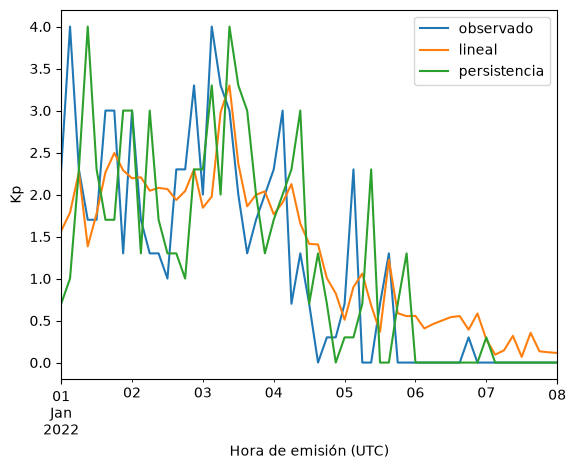

In [13]:
inicio = comparacion.index.min()
fin = inicio + pd.Timedelta(days=7)

comparacion.loc[inicio:fin].asfreq("3h").plot(
    xlabel="Hora de emisión (UTC)", ylabel="Kp"
);

In [14]:
# Entrenar el modelo final con entrenamiento y validación.
entrenamiento_final = pd.concat([train, val])

X_final = entrenamiento_final.drop(columns="kp_objetivo")
y_final = entrenamiento_final["kp_objetivo"]

modelo_final = LinearRegression()
modelo_final.fit(X_final, y_final)

# Predecir el Kp de los años reservados para test.
X_test = test.drop(columns="kp_objetivo")
y_test = test["kp_objetivo"]
pred_test = modelo_final.predict(X_test)

# Comparar los dos métodos en las mismas emisiones.
comparacion_test = pd.DataFrame({
    "observado": y_test,
    "lineal": pd.Series(pred_test, index=y_test.index),
    "persistencia": persistencia.reindex(y_test.index),
}).dropna()

mae_lineal = mean_absolute_error(comparacion_test["observado"], comparacion_test["lineal"])
mae_persistencia = mean_absolute_error(
    comparacion_test["observado"], comparacion_test["persistencia"]
)

print(f"Emisiones comparadas: {len(comparacion_test)} de {len(y_test)}")
print(f"MAE lineal en test: {mae_lineal:.3f}")
print(f"MAE persistencia en test: {mae_persistencia:.3f}")

Emisiones comparadas: 5703 de 5703
MAE lineal en test: 0.745
MAE persistencia en test: 0.863


In [15]:
import joblib

ruta_modelo = raiz / "data" / "processed" / "modelo_kp.joblib"
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(modelo_final, ruta_modelo)
print(f"Modelo guardado en: {ruta_modelo}")

Modelo guardado en: c:\Users\alvar\Desktop\ICAI-MÁSTER\Desarrollo_de_Soluciones_de_IA\pronostico-geomagnetico\data\processed\modelo_kp.joblib


In [16]:
modelo_cargado = joblib.load(ruta_modelo)

datos_viento = df_historico.drop(columns="kp_x10")
entradas = construir_dataset(datos_viento, incluir_objetivo=False)

emision = X_test.index[0]
fin_bloque = emision + pd.Timedelta(hours=3)
kp_predicho = modelo_cargado.predict(entradas.loc[[emision]])[0]

print(f"Bloque UTC: {emision:%Y-%m-%d %H:%M} a {fin_bloque:%H:%M}")
print(f"Kp predicho: {kp_predicho:.2f}")

Bloque UTC: 2024-01-01 00:00 a 03:00
Kp predicho: 1.36


In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

modelos = {
    "Boosting": HistGradientBoostingRegressor(early_stopping=False, random_state=42),
    "Random Forest": RandomForestRegressor(min_samples_leaf=20, random_state=42),
}

resultados = comparacion.copy()
X_comparacion = X_val.loc[resultados.index]

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    resultados[nombre] = modelo.predict(X_comparacion)

errores = resultados.drop(columns="observado").sub(resultados["observado"], axis=0).abs()

kp_alto = resultados["observado"] >= 5
print("Emisiones con Kp observado ≥ 5:", kp_alto.sum())

pd.DataFrame({
    "MAE global": errores.mean(),
    "MAE con Kp ≥ 5": errores.loc[kp_alto].mean(),
}).round(3)

Emisiones con Kp observado ≥ 5: 131


,MAE global,MAE con Kp ≥ 5
lineal,0.726,2.058
persistencia,0.888,1.841
Boosting,0.660,1.498
Random Forest,0.669,1.501


In [18]:
# Boosting es el mejor candidato por ello ajustamos con param_grid

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "max_leaf_nodes": [7, 15, 31],
    "min_samples_leaf": [20, 50],
}

busqueda = GridSearchCV(
    HistGradientBoostingRegressor(early_stopping=False, random_state=42),
    param_grid=param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error",
)
busqueda.fit(X_train, y_train)

pred_ajustada = busqueda.predict(X_comparacion)
error_ajustado = (resultados["observado"] - pred_ajustada).abs()

print("Mejores parámetros:", busqueda.best_params_)
print(f"MAE global ajustado: {error_ajustado.mean():.3f}")
print(f"MAE ajustado con Kp ≥ 5: {error_ajustado.loc[kp_alto].mean():.3f}")

Mejores parámetros: {'max_leaf_nodes': 15, 'min_samples_leaf': 50}
MAE global ajustado: 0.661
MAE ajustado con Kp ≥ 5: 1.509


In [19]:
boosting_final = HistGradientBoostingRegressor(
    early_stopping=False, random_state=42
)
boosting_final.fit(X_final, y_final)

resultados_test = comparacion_test.copy()
resultados_test["Boosting"] = boosting_final.predict(
    X_test.loc[resultados_test.index]
)

errores_test = resultados_test.drop(columns="observado")
errores_test = errores_test.sub(resultados_test["observado"], axis=0).abs()

kp_alto_test = resultados_test["observado"] >= 5
print("Emisiones con Kp ≥ 5 en test:", kp_alto_test.sum())

pd.DataFrame({
    "MAE global": errores_test.mean(),
    "MAE con Kp ≥ 5": errores_test.loc[kp_alto_test].mean(),
}).round(3)

Emisiones con Kp ≥ 5 en test: 249


,MAE global,MAE con Kp ≥ 5
lineal,0.745,1.780
persistencia,0.863,1.551
Boosting,0.675,1.335


In [20]:
joblib.dump(boosting_final, ruta_modelo)
print(f"Modelo Boosting guardado en: {ruta_modelo}")

Modelo Boosting guardado en: c:\Users\alvar\Desktop\ICAI-MÁSTER\Desarrollo_de_Soluciones_de_IA\pronostico-geomagnetico\data\processed\modelo_kp.joblib
